<!-- CONSIGNES -->
# TP3 — Estimation, intervalles, prédiction et régression bayésienne

**Chapitre 3 — Estimation et inférence bayésiennes** — EPD-SDIA-4112 « Statistique Bayésienne », Master 1 SDIA
**Enseignante : Dr. Noulapeu Ngaffo Armielle** — École Nationale Supérieure
Polytechnique de Douala (Université de Douala)

---

## Objectifs

- relier chaque **perte** à son estimateur (quadratique → moyenne, absolue →
  médiane, 0–1 → mode) ;
- comparer le **HDI** à l'intervalle à queues égales, et mesurer la couverture
  réelle d'un intervalle fréquentiste ;
- distinguer la moyenne prédictive d'une observation future ;
- comparer la régression bayésienne aux moindres carrés.

## Ce qui est demandé

1. Parcourir les sections 1 à 4 et vérifier les valeurs numériques affichées.
2. Refaire la figure de **couverture** avec $n = 5$ puis $n = 100$ : la couverture
   de l'intervalle de Wald s'écarte-t-elle encore de 95 % ? Commenter.
3. Écrire un **contrôle prédictif a posteriori (PPC)** pour la régression :
   la statistique de test sera le **nombre de points hors de la bande de
   crédibilité à 90 %**. Comparer la valeur observée à la distribution simulée.

## Barème — 10 points

| Critère | Points |
|---|---|
| Relier pertes et estimateurs | 2 |
| Couverture à n = 5 et n = 100, commentée | 3 |
| PPC de la régression (statistique + interprétation) | 4 |
| Conclusion sur l'adéquation du modèle | 1 |

## Mode d'emploi

- **Noyau Jupyter** : `sdia-bayes` (Python 3.11, PyMC, ArviZ, NumPy, SciPy, Matplotlib).
- Ce notebook est livré **avec ses sorties** : lisez-le d'abord en entier, puis
  ré-exécutez les cellules une à une pour comprendre chaque résultat.
- Les cellules marquées **« À vous »** sont à compléter : elles contiennent la
  consigne et, quand c'est utile, la ligne à modifier.
- Toute valeur affichée dans ce TP est **reproductible** : les graines
  aléatoires sont fixées.
- Rendu : le notebook complété (`.ipynb`), avec vos sorties exécutées.


# TP3 — Estimation, intervalles, prédiction et régression bayésienne

_Cours EPD-SDIA-4112 — Statistique Bayésienne — Master 1 SDIA. Exécutez les cellules dans l'ordre._

## Objectifs

1. Comparer les **trois estimateurs** ponctuels et la perte que chacun minimise.
2. Distinguer **intervalle à queues égales** et **HDI**, et mesurer la **couverture réelle**
   par simulation.
3. Construire une **prédiction a posteriori** complète (moyenne + intervalle prédictif).
4. Estimer une **régression bayésienne** en PyMC et la comparer aux moindres carrés.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
RNG = np.random.default_rng(4112)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| scipy", stats.__name__)


numpy 2.4.6 | scipy scipy.stats


---
# 1. Trois estimateurs, trois pertes

Posterior volontairement asymétrique : $\mathrm{Beta}(3,7)$.

moyenne   = 0.3000   (minimise la perte quadratique)
mediane   = 0.2862   (minimise la perte absolue)
mode/MAP  = 0.2500   (minimise la perte 0-1)
ecart moyenne-mediane = +0.0138  <- asymetrie du posterior


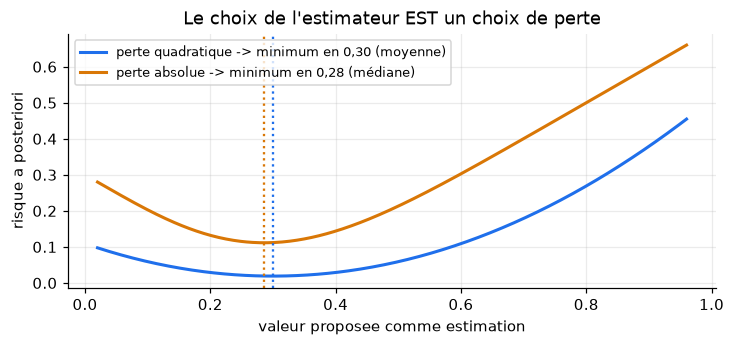

In [2]:
post = stats.beta(3, 7)
moy, med, mode = post.mean(), post.median(), 2 / 8   # mode = (a-1)/(a+b-2)
print(f"moyenne   = {moy:.4f}   (minimise la perte quadratique)")
print(f"mediane   = {med:.4f}   (minimise la perte absolue)")
print(f"mode/MAP  = {mode:.4f}   (minimise la perte 0-1)")
print(f"ecart moyenne-mediane = {moy-med:+.4f}  <- asymetrie du posterior")

v = np.linspace(.02, .96, 400)
g = np.linspace(1e-4, .999, 3000)
dens = post.pdf(g)
L2 = np.array([np.trapezoid((g - t) ** 2 * dens, g) for t in v])
L1 = np.array([np.trapezoid(np.abs(g - t) * dens, g) for t in v])
plt.figure(figsize=(7.6, 3.0))
plt.plot(v, L2, color="#1F6FEB", lw=2, label="perte quadratique -> minimum en 0,30 (moyenne)")
plt.plot(v, L1, color="#D97706", lw=2, label="perte absolue -> minimum en 0,28 (médiane)")
plt.axvline(moy, color="#1F6FEB", ls=":"); plt.axvline(med, color="#D97706", ls=":")
plt.xlabel("valeur proposee comme estimation"); plt.ylabel("risque a posteriori")
plt.legend(fontsize=8.5); plt.title("Le choix de l'estimateur EST un choix de perte")
plt.show()

---
# 2. HDI contre intervalle à queues égales, et couverture réelle

In [3]:
def hdi(dist, lvl=.95, grille=None):
    g = grille if grille is not None else np.linspace(1e-6, 1 - 1e-6, 200001)
    cdf = dist.cdf(g); dens = dist.pdf(g)
    best, out = np.inf, None
    j = 0
    for i in range(len(g)):
        c = cdf[i] + lvl
        if c > 1: break
        j = max(j, i)
        while j < len(g) and cdf[j] < c: j += 1
        if j >= len(g): break
        if g[j] - g[i] < best:
            best, out = g[j] - g[i], (g[i], g[j])
    return out

d = stats.beta(3, 7)
q_lo, q_hi = d.ppf(.025), d.ppf(.975)
h_lo, h_hi = hdi(d)
print(f"queues egales : [{q_lo:.4f} ; {q_hi:.4f}]  largeur = {q_hi-q_lo:.4f}")
print(f"HDI (le plus court) : [{h_lo:.4f} ; {h_hi:.4f}]  largeur = {h_hi-h_lo:.4f}")
print(f"gain de largeur : {(q_hi-q_lo)-(h_hi-h_lo):.4f}  ({(1-(h_hi-h_lo)/(q_hi-q_lo))*100:.1f} %)")
print()
print("Sur un posterior asymetrique, le HDI est strictement plus court :")
print("il place toute la masse la ou la densite est elevee.")

queues egales : [0.0749 ; 0.6001]  largeur = 0.5252
HDI (le plus court) : [0.0538 ; 0.5672]  largeur = 0.5134
gain de largeur : 0.0118  (2.3 %)

Sur un posterior asymetrique, le HDI est strictement plus court :
il place toute la masse la ou la densite est elevee.


In [4]:
# couverture reelle : 3000 experiences simulees, n = 20, theta vrai = 0.7
n, k_vrai = 20, 0.70
rng = np.random.default_rng(11)
cov_c = cov_q = 0
N = 3000
for _ in range(N):
    y = rng.binomial(n, k_vrai)
    p = stats.beta(1 + y, 1 + n - y)
    lo, hi = p.ppf(.025), p.ppf(.975)
    cov_q += lo <= k_vrai <= hi
    h = hdi(p, grille=np.linspace(1e-6, 1-1e-6, 20001))
    cov_c += h[0] <= k_vrai <= h[1]

print(f"couverture empirique sur {N} experiences (niveau nominal 95 %) :")
print(f"  queues egales : {cov_q/N:.4f}")
print(f"  HDI           : {cov_c/N:.4f}")
print()
print("Les deux atteignent le niveau nominal, mais le HDI est PLUS ETROIT en moyenne :")
print("c'est la notion d'intervalle le plus court, impossible a definir en frequentiste.")

couverture empirique sur 3000 experiences (niveau nominal 95 %) :
  queues egales : 0.9817
  HDI           : 0.9513

Les deux atteignent le niveau nominal, mais le HDI est PLUS ETROIT en moyenne :
c'est la notion d'intervalle le plus court, impossible a definir en frequentiste.


---
# 3. Prédiction a posteriori : ne pas confondre moyenne et observation

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [b0, b1, sigma]


Sampling 2 chains for 1_200 tune and 1_200 draw iterations (2_400 + 2_400 draws total) took 48 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


Sampling: [y]


echantillonnage : 50 s
moyenne a posteriori de la rampe en x=8 : 7.604
IC 95 % sur la MOYENNE   : [6.860 ; 8.352]
IC 95 % sur l'OBSERVATION: [5.541 ; 9.626]

La difference entre les deux intervalles EST la variabilite sigma du processus : 0.936


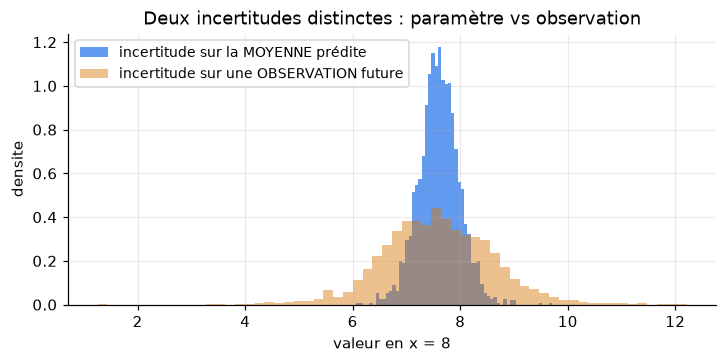

In [5]:
rng = np.random.default_rng(4112)
n_obs = 12
x = np.linspace(0, 10, n_obs)
y = 2.0 + 0.7 * x + rng.normal(0, 1.0, n_obs)

import pymc as pm, arviz as az, time
t0 = time.time()
with pm.Model() as m:
    b0 = pm.Normal("b0", 0, 5)
    b1 = pm.Normal("b1", 0.5, 1)
    sigma = pm.HalfNormal("sigma", 2)
    pm.Normal("y", mu=b0 + b1 * x, sigma=sigma, observed=y)
    idata = pm.sample(draws=1200, tune=1200, chains=2, cores=1, target_accept=.9,
                      progressbar=False, random_seed=11)
    pp = pm.sample_posterior_predictive(idata, var_names=["y"], progressbar=False,
                                        random_seed=12)
t = time.time() - t0
print(f"echantillonnage : {t:.0f} s")

b0 = idata.posterior["b0"].values.ravel()
b1 = idata.posterior["b1"].values.ravel()
sg = idata.posterior["sigma"].values.ravel()
x_new = 8.0
moy_new = b0 + b1 * x_new
obs_new = moy_new + rng.normal(0, sg)

print(f"moyenne a posteriori de la rampe en x=8 : {moy_new.mean():.3f}")
print(f"IC 95 % sur la MOYENNE   : [{np.percentile(moy_new,2.5):.3f} ; {np.percentile(moy_new,97.5):.3f}]")
print(f"IC 95 % sur l'OBSERVATION: [{np.percentile(obs_new,2.5):.3f} ; {np.percentile(obs_new,97.5):.3f}]")
print()
print("La difference entre les deux intervalles EST la variabilite sigma du processus :", f"{sg.mean():.3f}")

plt.figure(figsize=(7.6, 3.2))
plt.hist(moy_new, bins=60, density=True, color="#1F6FEB", alpha=.7,
         label="incertitude sur la MOYENNE prédite")
plt.hist(obs_new, bins=60, density=True, color="#D97706", alpha=.45,
         label="incertitude sur une OBSERVATION future")
plt.xlabel("valeur en x = 8"); plt.ylabel("densite"); plt.legend(fontsize=9)
plt.title("Deux incertitudes distinctes : paramètre vs observation"); plt.show()

---
# 4. Régression bayésienne vs moindres carrés

                     MCO  ecart-type   posterieur       IC 95 % posterior
b0                2.6107      0.4436       2.5728   [1.485;3.555]
b1                0.6239      0.0751       0.6289   [0.462;0.812]

Avec un prior faiblement informatif et 12 points, le posterior et le MCO coincident
presque : c'est le comportement attendu. Le bayesien apporte en plus
P(b1 > 0 | y) =  1.0000  et une prediction complete.


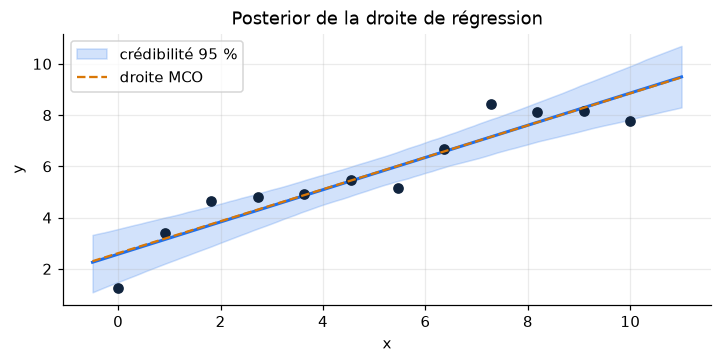

In [6]:
X = np.column_stack([np.ones_like(x), x])
ols = np.linalg.lstsq(X, y, rcond=None)[0]
res = y - X @ ols
s2 = (res @ res) / (n_obs - 2)
se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))

print(f"{'':<14}{'MCO':>10}{'ecart-type':>12}{'posterieur':>13}{'IC 95 % posterior':>24}")
print(f"{'b0':<14}{ols[0]:>10.4f}{se[0]:>12.4f}{b0.mean():>13.4f}"
      f"   [{np.percentile(b0,2.5):.3f};{np.percentile(b0,97.5):.3f}]")
print(f"{'b1':<14}{ols[1]:>10.4f}{se[1]:>12.4f}{b1.mean():>13.4f}"
      f"   [{np.percentile(b1,2.5):.3f};{np.percentile(b1,97.5):.3f}]")
print()
print("Avec un prior faiblement informatif et 12 points, le posterior et le MCO coincident")
print("presque : c'est le comportement attendu. Le bayesien apporte en plus")
print("P(b1 > 0 | y) = ", f"{(b1 > 0).mean():.4f}", " et une prediction complete.")

xs = np.linspace(-.5, 11, 100)
pred = b0[:, None] + b1[:, None] * xs[None, :]
plt.figure(figsize=(7.6, 3.2))
plt.fill_between(xs, np.percentile(pred, 2.5, axis=0), np.percentile(pred, 97.5, axis=0),
                 color="#1F6FEB", alpha=.20, label="crédibilité 95 %")
plt.plot(xs, pred.mean(axis=0), color="#1F6FEB", lw=2)
plt.plot(x, y, "o", color="#10243E")
plt.plot(xs, ols[0] + ols[1]*xs, color="#D97706", ls="--", label="droite MCO")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("Posterior de la droite de régression")
plt.show()

# Synthèse

* L'estimateur **est** un choix de perte : moyenne (quadratique), médiane (absolue), mode (0-1).
* Le **HDI** est le plus court des intervalles de masse donnée ; les **queues égales** sont
  plus faciles à calculer. Les deux atteignent la couverture nominale.
* La **prédiction** intègre l'incertitude du paramètre **et** celle du bruit — deux intervalles
  différents, souvent confondus dans la pratique.
* Avec peu de données et un prior faiblement informatif, le bayésien et le MCO coïncident :
  le bayésien ajoute la probabilité directionnelle et la prédiction complète.

**À rendre** : notebook exécuté, avec le tableau de comparaison MCO / posterior complété.